Utiliser la bibliothèque Pandas en Python permet de manipuler, nettoyer, analyser et transformer des données tabulaires (comme des tableaux Excel ou des bases de données) de manière rapide, flexible et automatisée

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


In [30]:
import os
os.getcwd()

'/home/mariam/Documents/diarrab/Intro2Python'

In [33]:
import os

print(os.listdir("dataset"))

['titanic.xls']


pandas a besoin du moteur <span style ='color :green;'>python-calamine </span>pour lire ton fichier Excel .xls, mais que ce module n'est pas installé dans ton environnement virtuel.

In [35]:
data = pd.read_excel('dataset/titanic.xls')

In [ ]:
#pour connaître la taille
data.shape
#les entêtes des colonnes
data.columns
# pour connaître les prémière ligne du data
data.head()
#NB: quand vous enlève les parathèse à head on deforme le tableau



,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [59]:
#verifiactio de la taille d'origine du dataset
data.shape

(120, 5)

In [52]:
print(data.columns.tolist())

['pclass', 'survived', 'sex', 'age', 'body']


éliminer une colonne  on utilise **drop** pour enlèves toute colonne sauf les colonne Nom et sexe


In [51]:
data = data.drop(columns=[
    'name', 'sibsp', 'parch', 'ticket', 'fare',
    'cabin', 'embarked', 'boat', 'home.dest'
])

KeyError: "['name', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked', 'boat', 'home.dest'] not found in axis"

In [ ]:
data.describe()

,pclass,survived,age,body
count,1309.000000,1309.000000,1046.000000,121.000000
mean,2.294882,0.381971,29.881135,160.809917
std,0.837836,0.486055,14.413500,97.696922
min,1.000000,0.000000,0.166700,1.000000
25%,2.000000,0.000000,21.000000,72.000000
50%,3.000000,0.000000,28.000000,155.000000
75%,3.000000,1.000000,39.000000,256.000000
max,3.000000,1.000000,80.000000,328.000000


In [58]:
data.shape

(120, 5)

![Mon Schéma](pictures/manquedo.png)

Si l'on regarde le petit tableau extrait, on peut voir, si l'on fait référence à la première colonne, qu'au niveau de la colonne age, il manque des données.
**OPTION1** :Remplacer par avec donnée par defaut.
avec la première option on peut coromptre le dataset

**OPTION2**:supprimer les lignes correspondant.

![Mon Schémas](pictures/datdro.png)

**OPTION2**

In [54]:
data = data.dropna(axis =0)

In [57]:
# la shape du dataset

data.shape

(120, 5)

In [60]:
#affichage du dataset
data.describe()

,pclass,survived,age,body
count,120.000000,120.0,120.000000,120.00000
mean,2.158333,0.0,36.283333,160.87500
std,0.850070,0.0,14.193698,98.10392
min,1.000000,0.0,2.000000,1.00000
25%,1.000000,0.0,25.750000,71.50000
50%,2.000000,0.0,33.500000,155.50000
75%,3.000000,0.0,46.000000,256.50000
max,3.000000,0.0,71.000000,328.00000


In [64]:
#pour connaître le nombre de personne dans une classe expécifiques par exemple classe1,classe2
data['pclass'].value_counts()

pclass
3    54
1    35
2    31
Name: count, dtype: int64

<Axes: xlabel='pclass'>

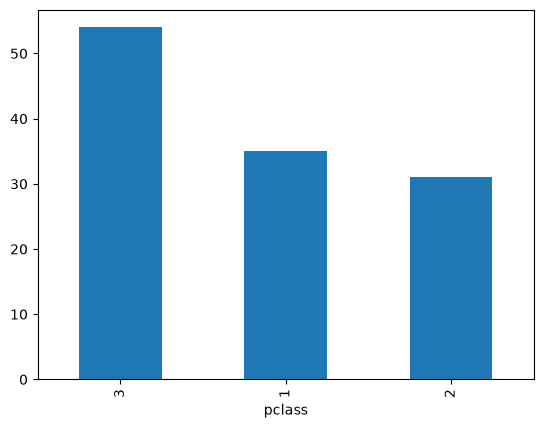

In [67]:
# si on veux présenter les donnée sous former de graphiques
data['pclass'].value_counts().plot.bar()


<Axes: >

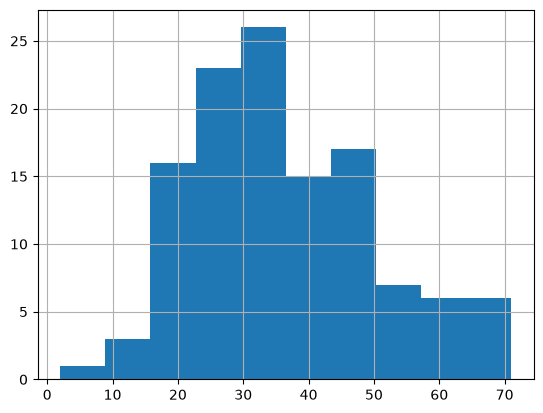

In [72]:
# On peut faire la répartition des age en histogramme
data['age'].hist()

In [78]:
# faire une analyse en regroupant les gens par sex avec la fonction group.by
#data.groupby(['sex'])
# après on peut appliques une méthode statistiques
data.groupby(['sex','pclass']).mean()

survived        age        body
sex    pclass                                 
female 2            0.0  57.000000   52.000000
       3            0.0  28.214286  183.000000
male   1            0.0  46.614286  162.828571
       2            0.0  33.850000  171.233333
       3            0.0  30.904255  151.829787

Dans la bibliothèque Pandas, il existe principalement deux structures de données fondamentales :

1. La Series

• Définition : Un tableau unidimensionnel (une seule colonne).
• Caractéristique : Elle est étiquetée, ce qui signifie que chaque élément possède un index (une clé). Toutes les données d'une Series doivent être du même type.
• Analogie : Une seule colonne extraite d'un tableau Excel.

2. Le DataFrame

• Définition : Un tableau bidimensionnel (lignes et colonnes).
• Caractéristique : C'est la structure principale de Pandas. Les colonnes peuvent être de types différents (par exemple : du texte dans la colonne "Nom" et des nombres dans la colonne "Âge"). Un DataFrame est en réalité un assemblage de plusieurs Series qui partagent le même index.
• Analogie : Une feuille de calcul complète dans Excel ou une table SQL.